In [6]:
!pip install -q kaggle pandas numpy scikit-learn

In [16]:
import kagglehub
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [17]:
path = kagglehub.dataset_download("uciml/glass")
print("Dataset Path:", path)

for file in os.listdir(path):
    if file.endswith(".csv"):
        csv_file = os.path.join(path, file)
        break

df = pd.read_csv(csv_file)

print(df.head())
print(df.info())

Using Colab cache for faster access to the 'glass' dataset.
Dataset Path: /kaggle/input/glass
        RI     Na    Mg    Al     Si     K    Ca   Ba   Fe  Type
0  1.52101  13.64  4.49  1.10  71.78  0.06  8.75  0.0  0.0     1
1  1.51761  13.89  3.60  1.36  72.73  0.48  7.83  0.0  0.0     1
2  1.51618  13.53  3.55  1.54  72.99  0.39  7.78  0.0  0.0     1
3  1.51766  13.21  3.69  1.29  72.61  0.57  8.22  0.0  0.0     1
4  1.51742  13.27  3.62  1.24  73.08  0.55  8.07  0.0  0.0     1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9  

In [18]:
print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

Missing values:
 RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64
Duplicates: 1


In [19]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [21]:
imputer = SimpleImputer(strategy="mean")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [22]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "SVM": SVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

results = []
predictions = {}

In [23]:
for name, model in models.items():

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="weighted")

    results.append([name, acc, f1])

    print(f"{name} | Accuracy={acc:.4f} | F1={f1:.4f}")

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression | Accuracy=0.6744 | F1=0.6547
SVM | Accuracy=0.3488 | F1=0.1804
Decision Tree | Accuracy=0.6977 | F1=0.6930
Random Forest | Accuracy=0.8372 | F1=0.8355


In [24]:
best_model = max(results, key=lambda x: x[1])

print("\nBest Model:", best_model[0])
print("Accuracy:", best_model[1])


Best Model: Random Forest
Accuracy: 0.8372093023255814


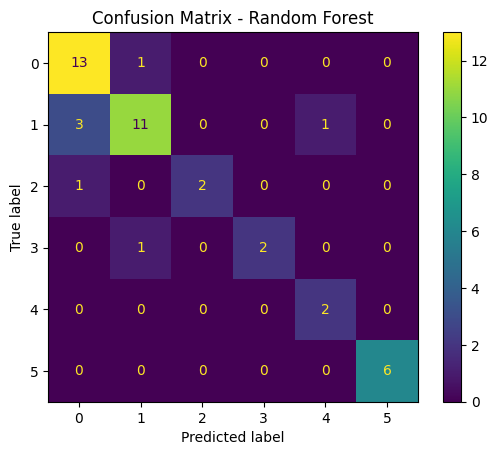

In [25]:
best_name = best_model[0]
best_pred = predictions[best_name]

cm = confusion_matrix(y_test, best_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

In [26]:
cv_scores = cross_val_score(
    models["Random Forest"],
    X_train,
    y_train,
    cv=5
)

print("Cross Validation Score:", cv_scores.mean())

Cross Validation Score: 0.7781512605042017


In [27]:
print("\nMODEL COMPARISON")
print("-" * 50)

for r in results:
    print(f"{r[0]:25} Accuracy={r[1]:.4f} F1={r[2]:.4f}")


MODEL COMPARISON
--------------------------------------------------
Logistic Regression       Accuracy=0.6744 F1=0.6547
SVM                       Accuracy=0.3488 F1=0.1804
Decision Tree             Accuracy=0.6977 F1=0.6930
Random Forest             Accuracy=0.8372 F1=0.8355


In [28]:
report = "Glass Dataset ML Report\n"
report += "="*40 + "\n\n"

for r in results:
    report += f"{r[0]} | Accuracy={r[1]:.4f} | F1={r[2]:.4f}\n"

report += f"\nBest Model: {best_model[0]}\n"
report += f"Best Accuracy: {best_model[1]:.4f}\n"
report += f"CV Score (Random Forest): {cv_scores.mean():.4f}\n"

with open("model_report.txt", "w") as f:
    f.write(report)

print("Report saved!")

Report saved!


In [29]:
from google.colab import files
files.download("model_report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
readme = """
# Glass Classification ML Project

## Description
This project compares multiple machine learning models on the Glass dataset.

## Steps
- Data validation
- Missing value handling
- Feature scaling
- Train/test split
- Model training
- Evaluation using Accuracy and F1-score

## Models Used
- Logistic Regression
- SVM
- Decision Tree
- Random Forest

## Best Model
Random Forest achieved the highest performance.

## Metrics
Accuracy and Weighted F1-score were used due to multi-class classification.

## Output
- model_report.txt
- confusion matrix plot
"""

with open("README.md", "w") as f:
    f.write(readme)

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>